# Лабораторна робота №3 — регресійне моделювання Gapminder

**Власенко Андрій, КН-41 · Python · 18.11.2026**

Продовження EDA лабораторної №2: 142 країни × 12 років = 1704 спостереження. Ціль — `lifeExp` (роки). Для оцінки прогнозу на **нових країнах** відокремлюємо тест за країнами та використовуємо групову 5-fold CV.

> Після EDA всього датасету в №2 гіпотези вважаються розвідувальними. Дані тесту №3 не використовуються для вибору моделі. **Запускайте з кореня проєкту**, обравши Python із `.venv`.

## 1. Підготовка та відтворюваний запуск

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data' / 'raw' / 'gapminder.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'raw' / 'gapminder.csv').exists(), 'Відкрийте корінь папки Lab03 у VS Code'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.analysis import run_analysis
result = run_analysis(ROOT)
print('Успішне виконання моделей, графіків і таблиць')

ЛР №3 · Gapminder · груповий поділ країн
Навчання: 1272 рядків / 106 країн; тест: 432 / 36 країн

5-fold CV (групи = країни):
       model  MAE_mean  MAE_std  RMSE_mean  RMSE_std
  Взаємодія     4.443    0.523      5.856     0.717
Квадратична     4.527    0.452      5.885     0.760
    Лінійна     4.577    0.465      5.911     0.698
   Орієнтир    11.455    1.142     13.082     1.118

Обрана за CV модель: Взаємодія

Незалежний тест (один раз):
     model    MAE   RMSE
 Орієнтир 11.620 13.178
Взаємодія  4.424  5.972

Згенеровано: outputs/figures/, outputs/tables/, outputs/metadata/
Успішне виконання моделей, графіків і таблиць


## 2. Якість даних та груповий holdout

In [2]:
display(result['train_stats'].round(3))
print('Навчальні країни:', result['train']['country'].nunique())
print('Тестові країни:', result['test']['country'].nunique())
print('Перетин країн:', set(result['train'].country) & set(result['test'].country))
assert set(result['train'].country).isdisjoint(result['test'].country)

,n_train,n_countries_train,n_test,n_countries_test,train_lifeExp_mean,train_lifeExp_median,train_lifeExp_std,train_lifeExp_min,train_lifeExp_max,train_logGDP_lifeExp_pearson_r,missing_values,duplicate_country_year
0,1272,106,432,36,59.597,60.654,12.828,23.599,81.757,0.803,0,0


Навчальні країни: 106
Тестові країни: 36
Перетин країн: set()


## 3. EDA лише навчальної частини

Логарифм ВВП, рік і континент обрані з огляду на джерела та лабораторну №2; нижче — *train-only* графіки.

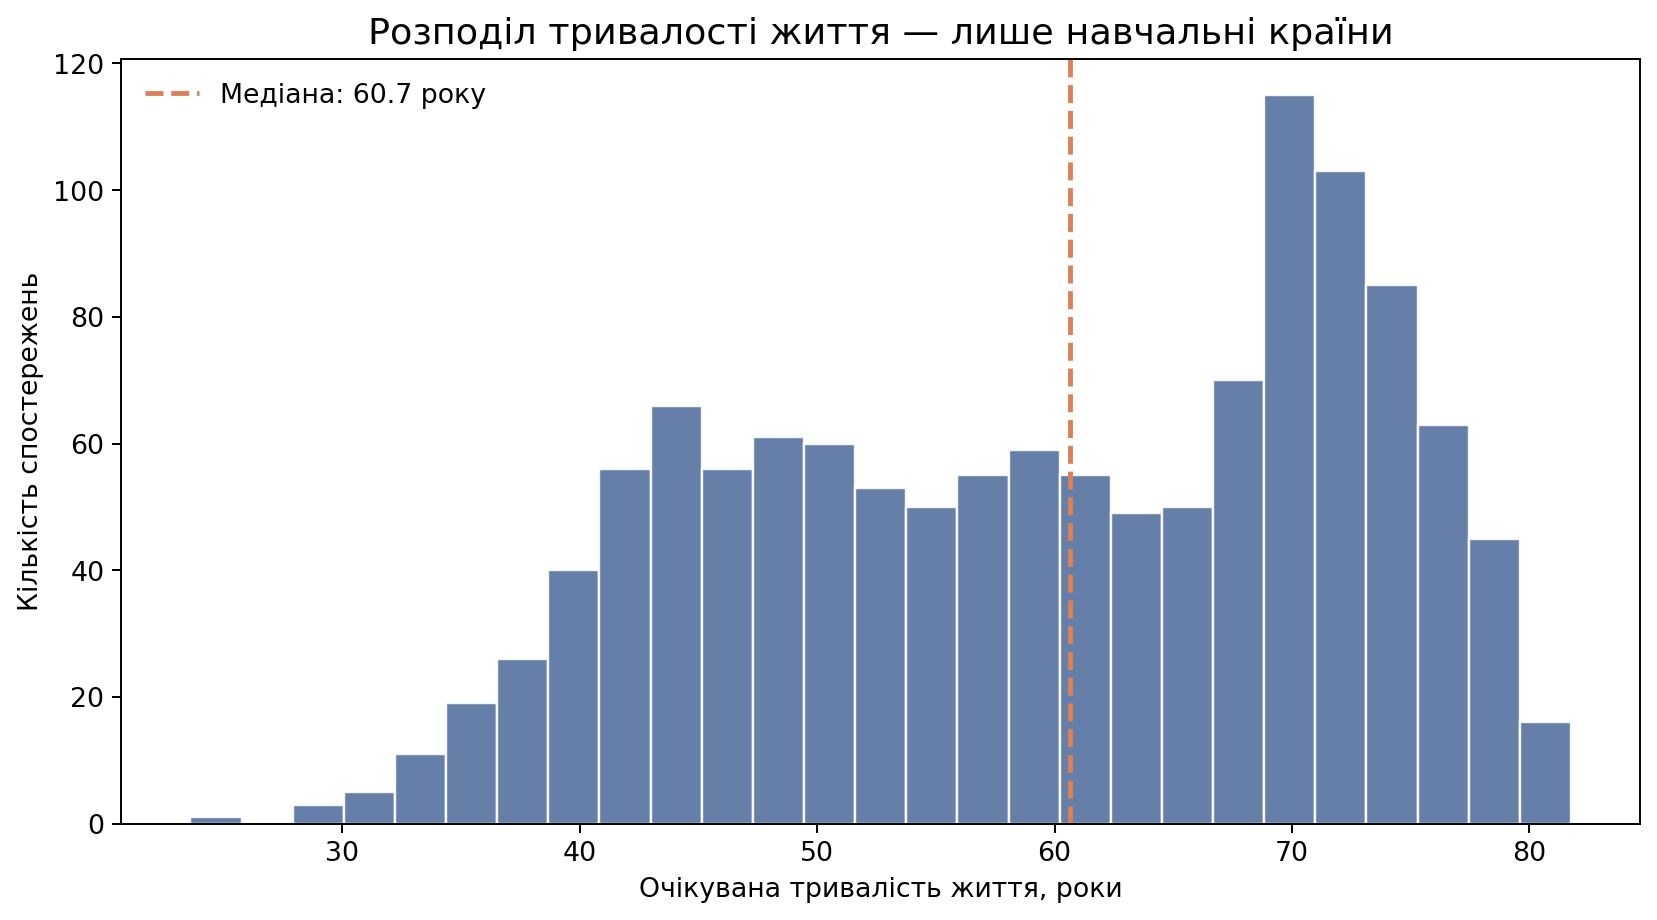

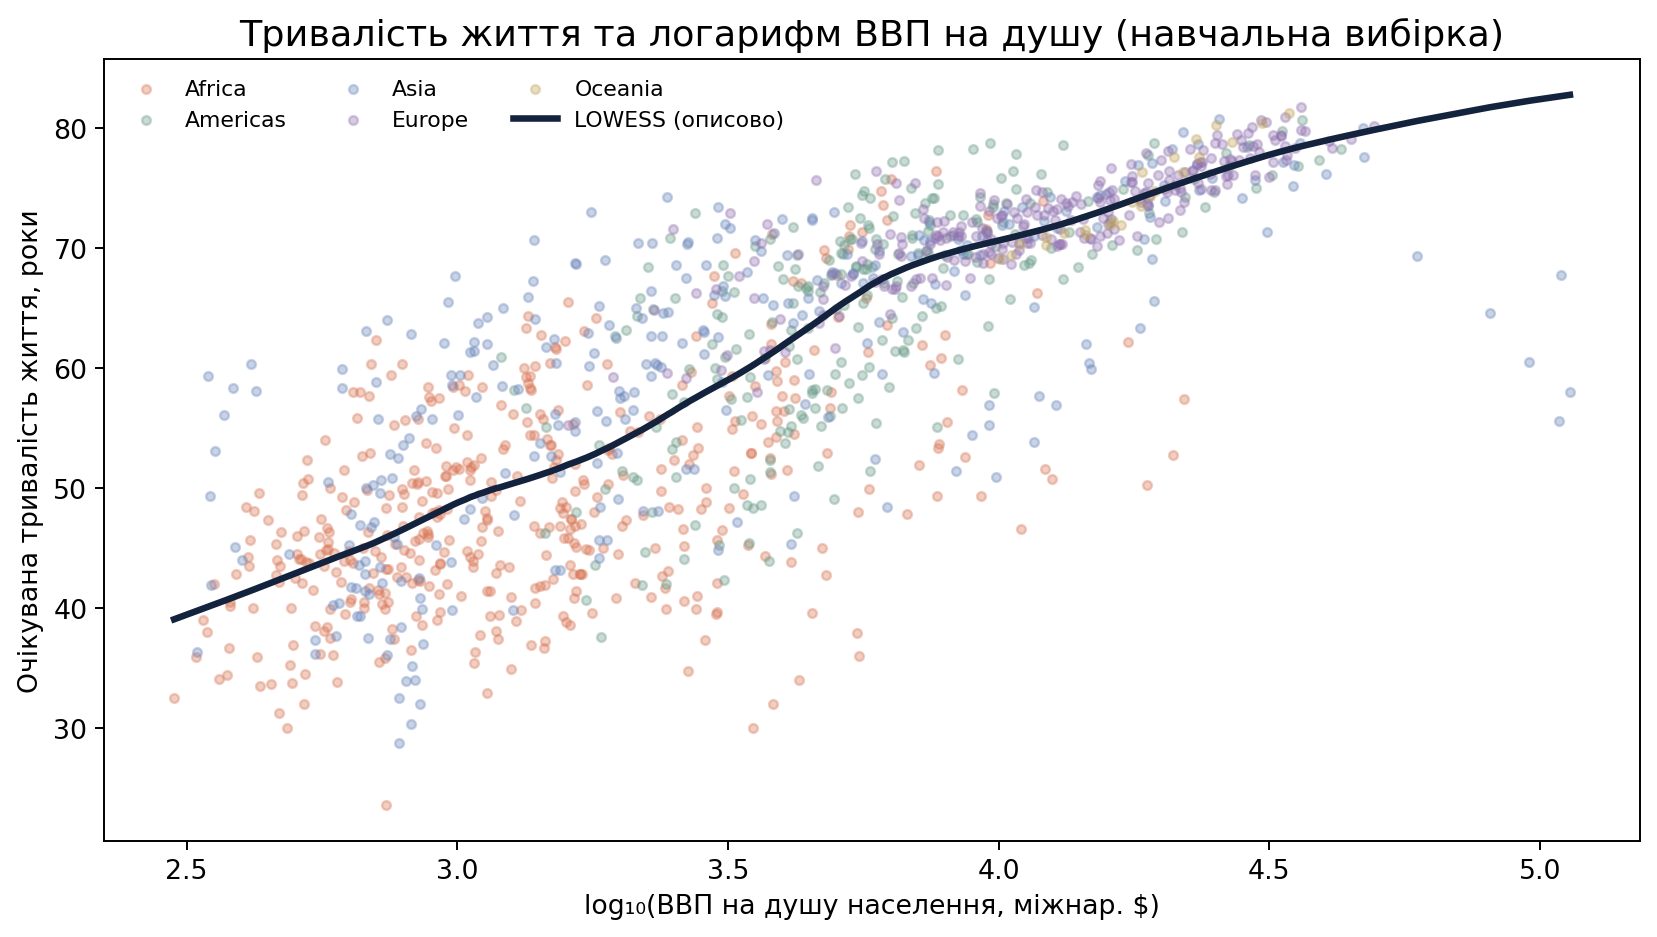

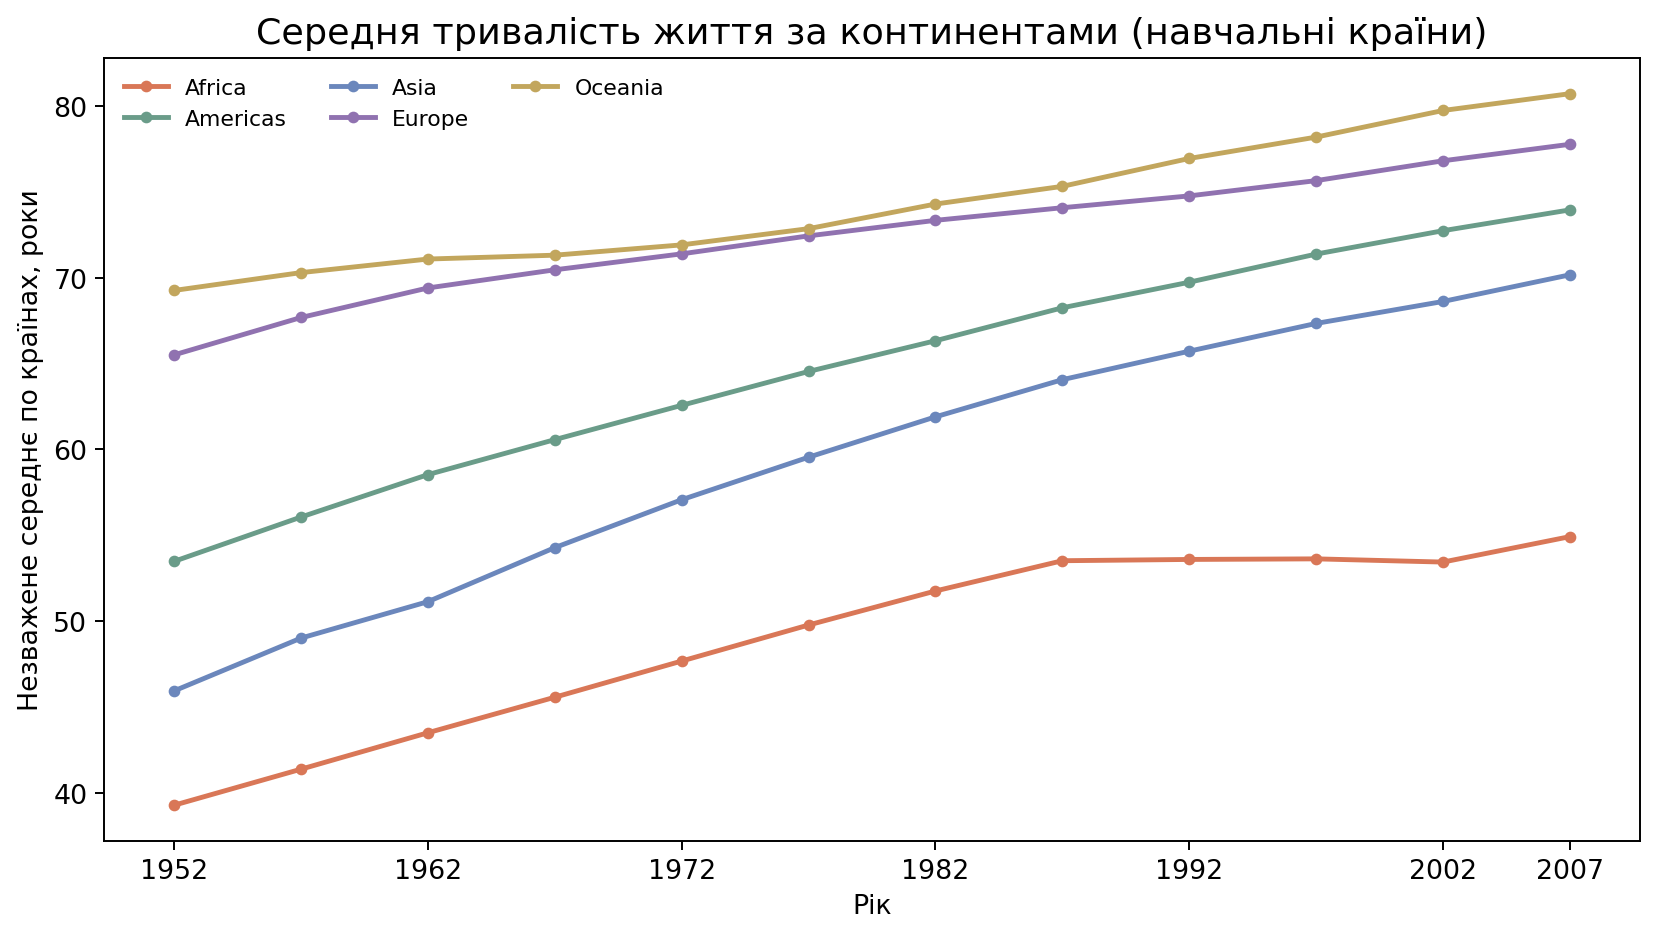

In [3]:
for name in ['01_train_target.png', '02_train_income.png', '03_train_time.png']:
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / name), width=780))

## 4. План моделей і групова перехресна валідація

Порівняно константне середнє, базову OLS, OLS з квадратичним членом та OLS із взаємодією доходу та континенту. Всі моделі використовують однакові 5 групових фолдів. Первинна метрика **RMSE** у роках.

,fold,model,n_validation,n_countries,MAE,RMSE
0,1,Орієнтир,264,22,11.007,12.844
1,1,Лінійна,264,22,4.691,6.480
2,1,Квадратична,264,22,4.832,6.634
3,1,Взаємодія,264,22,4.540,6.440
4,2,Орієнтир,252,21,10.193,11.941
5,2,Лінійна,252,21,4.281,5.416
6,2,Квадратична,252,21,4.545,5.654
7,2,Взаємодія,252,21,4.115,5.217
8,3,Орієнтир,252,21,12.929,14.697
9,3,Лінійна,252,21,5.323,6.829


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,Взаємодія,4.443,0.523,5.856,0.717
1,Квадратична,4.527,0.452,5.885,0.760
2,Лінійна,4.577,0.465,5.911,0.698
3,Орієнтир,11.455,1.142,13.082,1.118


Обрана модель (до тесту): Взаємодія


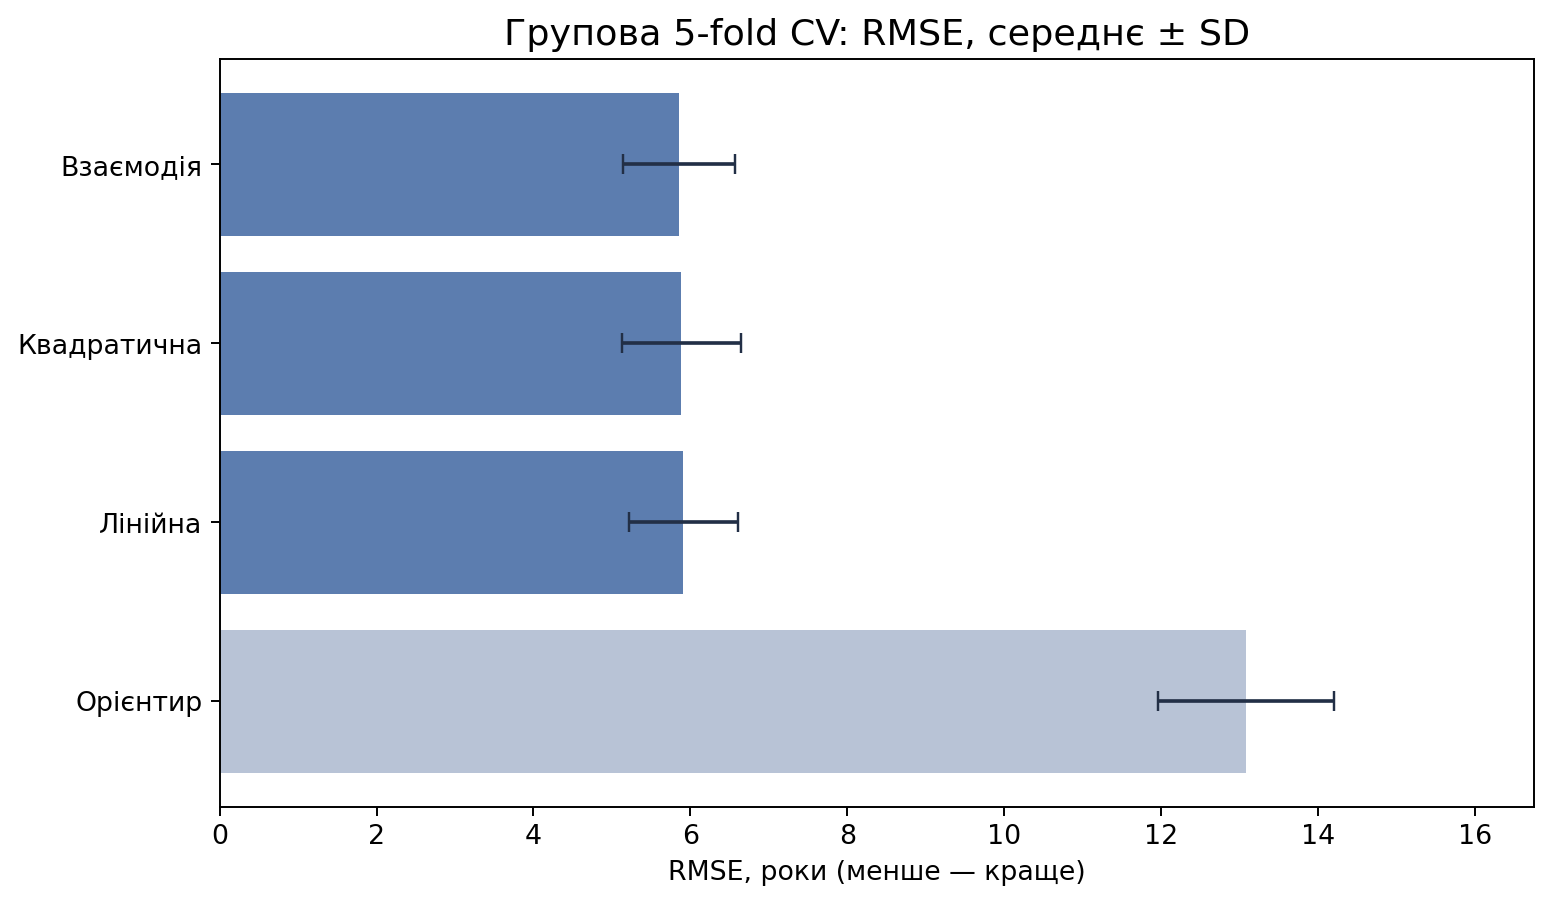

In [4]:
display(result['cv_folds'].round(3))
display(result['cv_summary'].round(3))
print('Обрана модель (до тесту):', result['selected'])
display(Image(filename=str(ROOT / 'outputs' / 'figures' / '06_cv_comparison.png'), width=780))

## 5. Гіпотези та кластерні 95% довірчі інтервали

**H1:** позитивний зв’язок `log10_gdp` з `lifeExp` за контролю року та континенту. **H2:** позитивний зв’язок `year_5`. Нижче — базова OLS з кластерними стандартними похибками за країною, а не коефіцієнти адаптивно обраної моделі.

In [5]:
display(result['coefficients'].round(4))
for term in ['log10_gdp', 'year_5']:
    row = result['coefficients'].set_index('term').loc[term]
    print(f"{term}: {row['estimate']:.3f}; кластерний 95% ДІ [{row['ci_low']:.3f}; {row['ci_high']:.3f}]")

,term,estimate,ci_low,ci_high,p_value_clustered
0,Intercept,6.8957,-0.4953,14.2867,0.0671
1,C(continent)[T.Americas],9.0872,5.8638,12.3106,0.0000
2,C(continent)[T.Asia],7.1719,4.0521,10.2917,0.0000
3,C(continent)[T.Europe],13.0741,9.8397,16.3084,0.0000
4,C(continent)[T.Oceania],13.1211,9.5750,16.6671,0.0000
5,log10_gdp,11.2165,8.6614,13.7715,0.0000
6,year_5,1.2140,1.0232,1.4049,0.0000


log10_gdp: 11.216; кластерний 95% ДІ [8.661; 13.772]
year_5: 1.214; кластерний 95% ДІ [1.023; 1.405]


## 6. Залишки та впливові спостереження

Перевірено гетероскедастичність тестом Бройша—Пагана й впливові точки за Куком. Незвичні історичні спостереження не вилучаємо автоматично.

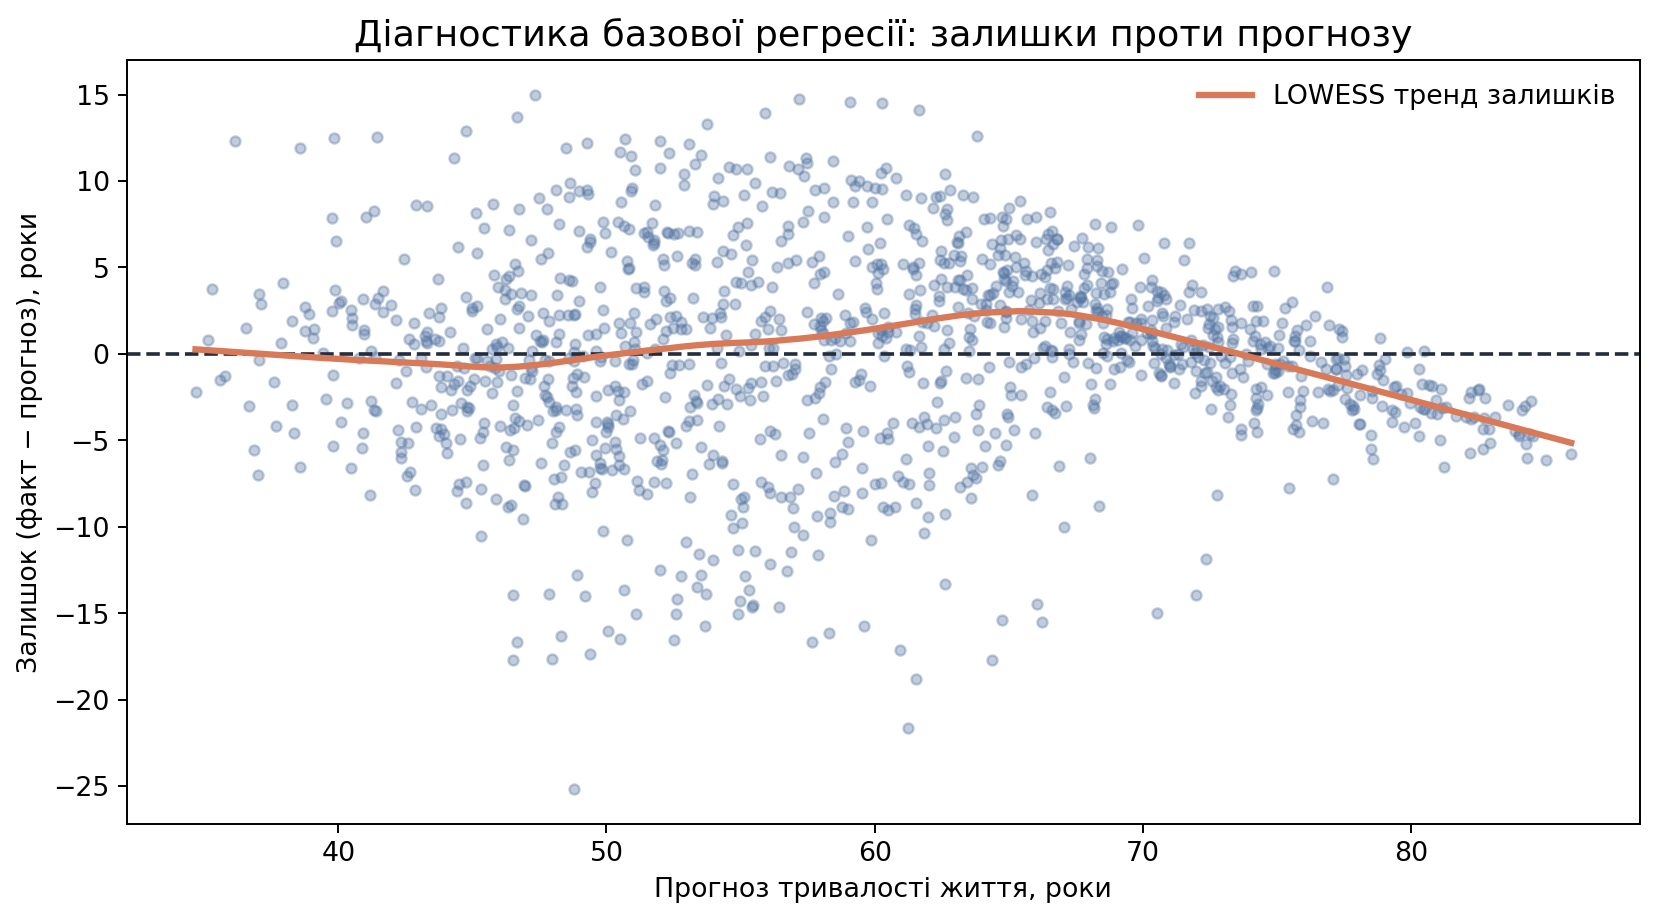

Діагностика: {'bp_lm_p_value': 2.2796903426807523e-14, 'bp_f_p_value': 8.564199160094094e-15, 'cook_threshold_4_over_n': 0.0031446540880503146, 'n_cook_above_threshold': 59, 'max_cook_distance': 0.022651344931583457, 'base_training_r_squared': 0.7985990127755048}


,country,year,continent,lifeExp,cooks_distance,studentized_residual,leverage
612,Kuwait,1952,Asia,55.565,0.0227,-2.6312,0.0225
613,Kuwait,1957,Asia,58.033,0.0188,-2.4485,0.0215
614,Kuwait,1962,Asia,60.470,0.0119,-2.0815,0.0189
11,Afghanistan,2007,Asia,43.828,0.0099,-2.9873,0.0078
1091,Swaziland,2007,Africa,39.613,0.0095,-3.7763,0.0047
968,Rwanda,1992,Africa,23.599,0.0093,-4.4012,0.0034
10,Afghanistan,2002,Asia,42.129,0.0089,-2.8215,0.0078
106,Botswana,2002,Africa,46.634,0.0087,-3.0934,0.0064
0,Afghanistan,1952,Asia,28.801,0.0083,-3.0874,0.0061
107,Botswana,2007,Africa,50.728,0.0076,-2.7028,0.0072


In [6]:
display(Image(filename=str(ROOT / 'outputs' / 'figures' / '04_base_residuals.png'), width=780))
print('Діагностика:', result['diagnostics'])
display(result['influential'].head(10).round(4))

## 7. Одноразовий відкладений тест і помилки

Модель зафіксована за CV та перенавчена на всіх навчальних країнах. Нижче — єдина оцінка на 36 відкладених країнах.

,model,MAE,RMSE
0,Орієнтир,11.620,13.178
1,Взаємодія,4.424,5.972


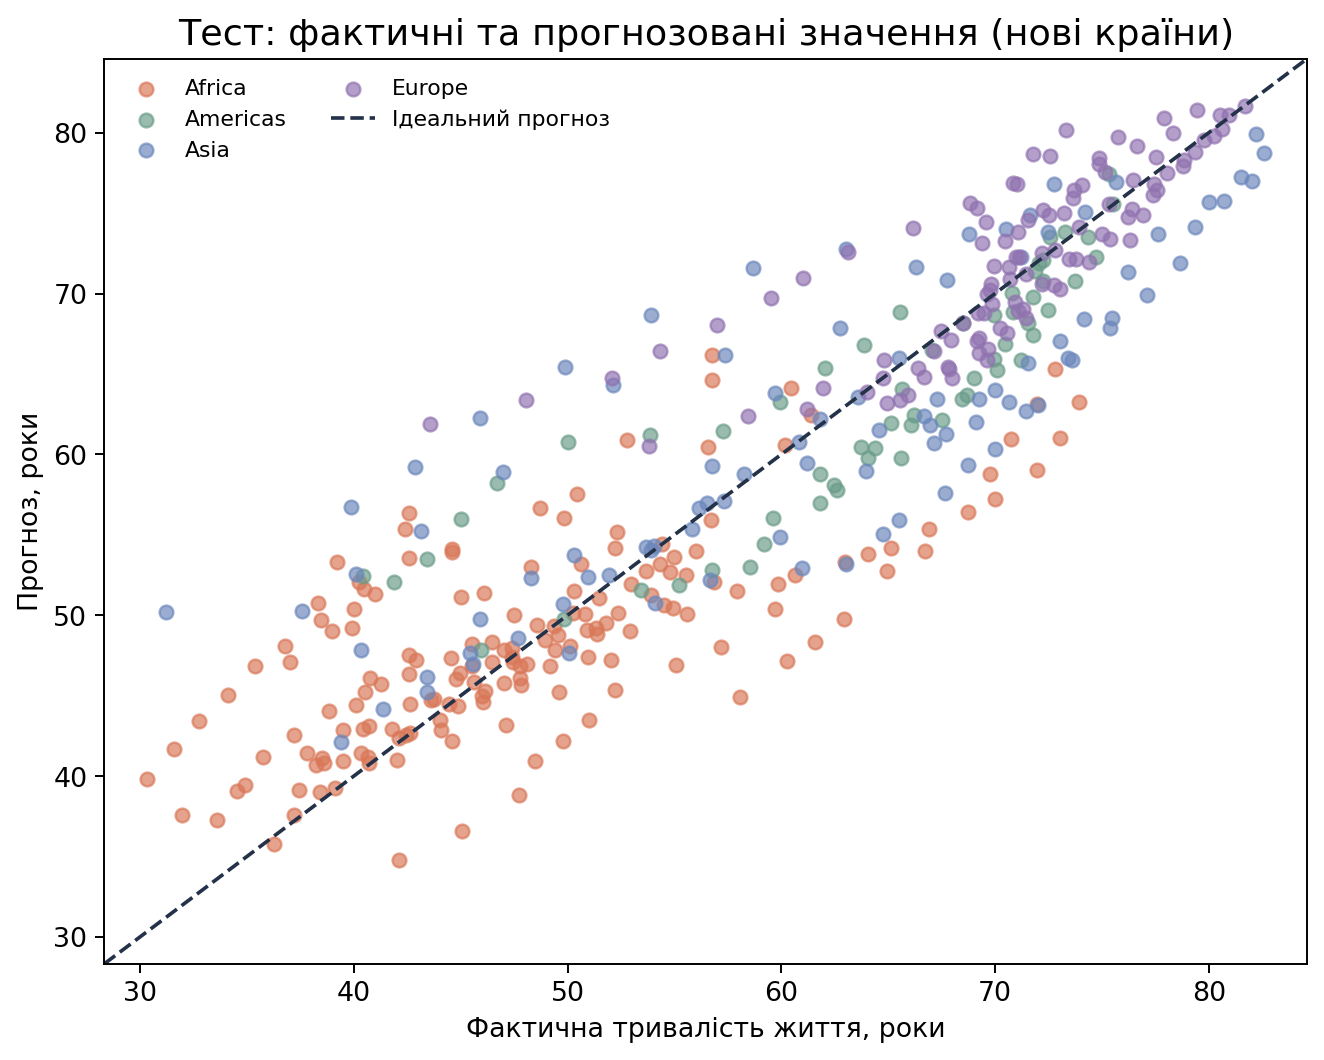

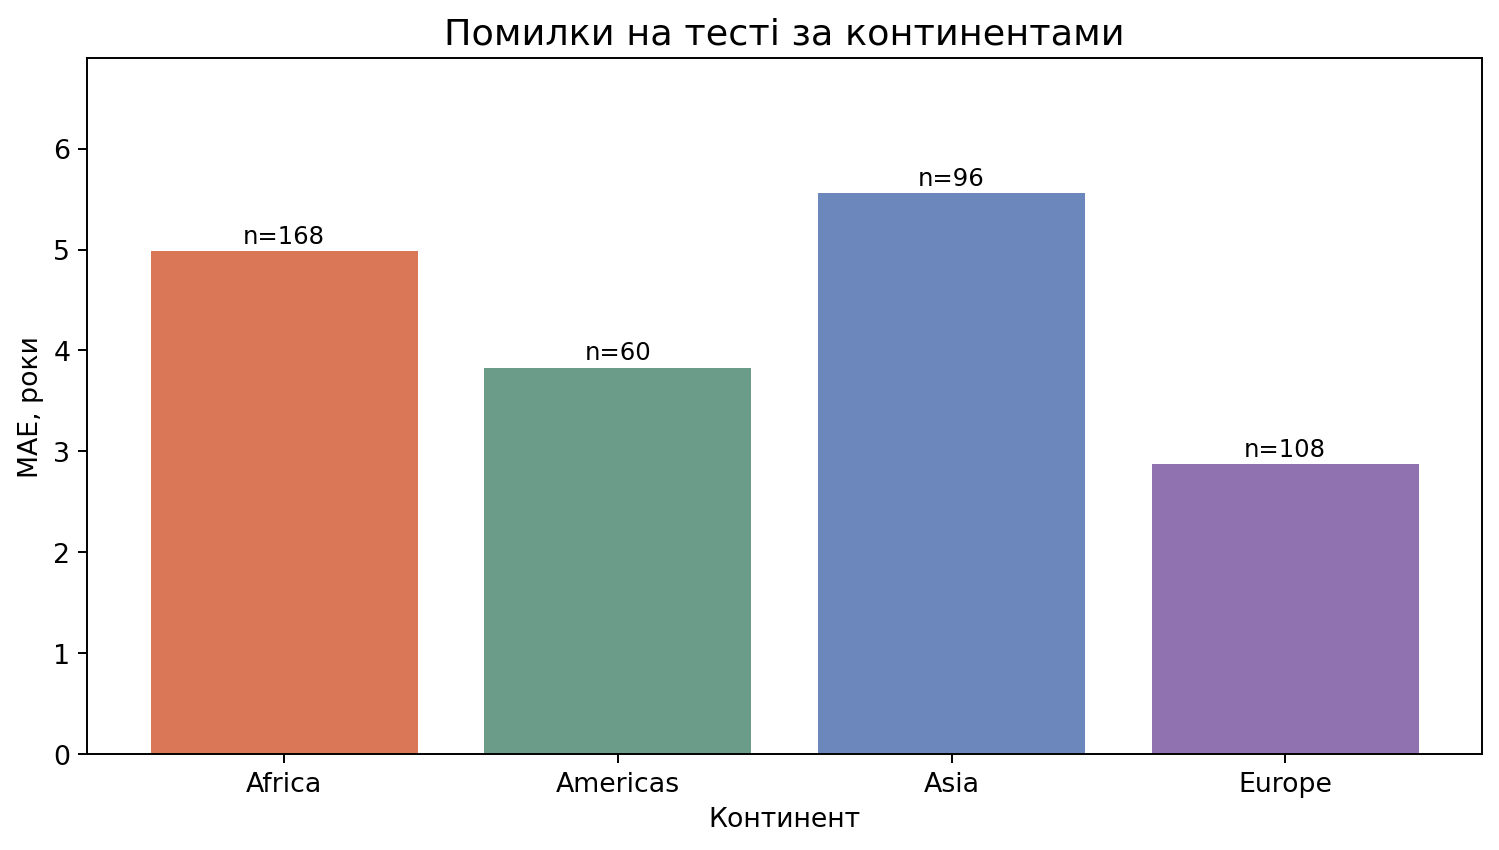

,country,continent,year,lifeExp,gdpPercap,selected_prediction,baseline_prediction,error,abs_error
77,Cambodia,Asia,1977,31.220,524.972,50.207,59.597,-18.987,18.987
408,Turkey,Europe,1952,43.585,1969.101,61.893,59.597,-18.308,18.308
324,Saudi Arabia,Asia,1952,39.875,6459.555,56.740,59.597,-16.865,16.865
326,Saudi Arabia,Asia,1962,45.914,11626.420,62.270,59.597,-16.356,16.356
325,Saudi Arabia,Asia,1957,42.868,8157.591,59.196,59.597,-16.328,16.328
327,Saudi Arabia,Asia,1967,49.901,16903.049,65.446,59.597,-15.545,15.545
409,Turkey,Europe,1957,48.079,2218.754,63.392,59.597,-15.313,15.313
328,Saudi Arabia,Asia,1972,53.886,24837.429,68.677,59.597,-14.791,14.791
430,Zambia,Africa,2002,39.193,1071.614,53.313,59.597,-14.120,14.120
251,Lesotho,Africa,2007,42.592,1569.331,56.333,59.597,-13.741,13.741


In [7]:
display(result['test_scores'].round(3))
for name in ['05_test_actual_vs_pred.png', '07_test_error_continents.png']:
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / name), width=780))
display(result['test_details'].sort_values('abs_error',ascending=False).head(10).round(3))

## 8. Висновок

Модель із взаємодією має найменший середній RMSE на груповій CV; на відкладених нових країнах її похибка становить близько **5,97 року RMSE** проти **13,18** для константного прогнозу. H1 і H2 заздалегідь оцінені базовою OLS та отримали позитивні кластерні 95% ДІ. Асоціації не є причинними ефектами. Велика гетероскедастичність і впливові спостереження обмежують упевненість у прогнозі; дані історичні (1952–2007).

Повний IMRaD-звіт — `reports/report.qmd` та `reports/report.html`; презентація — `reports/Presentation.pptx`, текст виступу — `reports/defense_script.md`.